# EDA: sprzedaż w czasie (część I) i w podziale na klasy A/B/C/D (część II)
Rok, miesiąc, dzień tygodnia i święta. Sprzedaż = wiersze z `TypDok == 21` i `DokId != -1` (puste dni i ruchy magazynowe nie wchodzą do liczenia).

Źródło danych: `dane/interim/fact_inka_final.parquet` (klucz towaru to `SKU`; kalendarz — `CzySwieto`, `CzyZamkniety`, `CzyNiedzielaHandlowa` — bierzemy z pliku, a nie liczymy drugi raz).

In [1]:
# Importy, ustawienia wykresów i katalog główny projektu
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import holidays
from dateutil.easter import easter

def swieta_polska(years):
    # nazwy świąt po polsku niezależnie od domyślnego języka biblioteki; daty ruchome liczymy osobno (easter)
    try:
        return holidays.Poland(years=years, language="pl")
    except TypeError:                      # starsza wersja biblioteki bez parametru language
        return holidays.Poland(years=years)

if os.path.basename(os.getcwd()) != "analiza_sprzedazy_w_sklepie":
    os.chdir("../..")

# Kolory: kolejność jak w palecie (niebieski, pomarańczowy, morski); szary dla tła i siatki
NIEB, POM, MOR, SZARY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
LATA_KOL = {2023: NIEB, 2024: POM, 2025: MOR}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})
zl = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))   # 12 345
DNI = ["Pn", "Wt", "Śr", "Cz", "Pt", "So", "Nd"]
MIES = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]

In [2]:
# Wczytanie tylko potrzebnych kolumn (cały plik jest duży)
PLIK = "dane/interim/fact_inka_final.parquet"
kol = ["SKU", "Data", "DokId", "TypDok", "IloscPlus", "Wartosc"]
df = pd.read_parquet(PLIK, columns=kol)

# Kalendarz z pliku: jeden wiersz na dzień (cechy dnia są takie same dla wszystkich towarów)
KOL_KAL = ["CzySwieto", "CzyZamkniety", "CzyNiedzielaHandlowa", "CzyDlugiWeekend", "CzyRoboczy"]
kal_pq = pd.read_parquet(PLIK, columns=["Data"] + KOL_KAL).drop_duplicates()
assert kal_pq["Data"].is_unique, "kalendarz w pliku nie jest jednoznaczny (różne flagi dla tej samej daty)"
kal_pq = kal_pq.set_index("Data").sort_index()

sprzedaz = df[(df["DokId"] != -1) & (df["TypDok"] == 21)]
print(f"Wierszy sprzedaży: {len(sprzedaz):,}".replace(",", " "))
print(f"Zakres dat sprzedaży: {sprzedaz['Data'].min().date()} … {sprzedaz['Data'].max().date()}")
print(sprzedaz[["IloscPlus", "Wartosc"]].describe().round(2))
del df

Wierszy sprzedaży: 3 373 975
Zakres dat sprzedaży: 2023-01-02 … 2026-01-31


        IloscPlus     Wartosc
count  3373975.00  3373975.00
mean         1.08        5.36
std          0.77        5.53
min          0.00        0.01
25%          1.00        2.66
50%          1.00        4.06
75%          1.00        6.47
max        100.00      634.15


## 1. Sprzedaż dzienna
Dla każdego dnia: wartość sprzedaży (`Wartosc`), liczba paragonów (unikalne `DokId`), liczba pozycji i średnia wartość paragonu. Dni bez sprzedaży dostają 0.

In [3]:
# Tabela dzienna na pełnym kalendarzu (dni bez sprzedaży = 0)
dz = sprzedaz.groupby("Data").agg(
    Wartosc=("Wartosc", "sum"),
    Sztuki=("IloscPlus", "sum"),
    Paragony=("DokId", "nunique"),
    Pozycje=("DokId", "size"),
)
kalendarz = pd.date_range(dz.index.min(), dz.index.max(), freq="D")
dz = dz.reindex(kalendarz, fill_value=0)
dz.index.name = "Data"
dz["Rok"] = dz.index.year
dz["Miesiac"] = dz.index.month
dz["DzienTyg"] = dz.index.dayofweek          # 0 = poniedziałek
dz["Handlowy"] = dz["Wartosc"] > 0           # dzień, w którym była sprzedaż
dz["SredniParagon"] = (dz["Wartosc"] / dz["Paragony"]).where(dz["Paragony"] > 0)

# Święta państwowe: nazwy z biblioteki holidays (zna ruchome, np. Wielkanoc i Boże Ciało),
# a flaga dnia z pliku (CzySwieto). Obie listy muszą się zgadzać w zakresie danych.
sw = swieta_polska(range(dz.index.year.min(), dz.index.year.max() + 1))
swieta = pd.Series({pd.Timestamp(d): n for d, n in sw.items()}).sort_index()
dz["Swieto"] = kal_pq["CzySwieto"].reindex(dz.index).eq(1)
dz["Zamkniety"] = kal_pq["CzyZamkniety"].reindex(dz.index).eq(1)
dz["NdHandlowaPrawo"] = kal_pq["CzyNiedzielaHandlowa"].reindex(dz.index).eq(1)
assert set(dz.index[dz["Swieto"]]) == set(swieta.index[(swieta.index >= dz.index.min()) & (swieta.index <= dz.index.max())]), \
    "CzySwieto z pliku różni się od biblioteki holidays"
# kontrola: dzień bez sprzedaży to dokładnie dzień zamknięty według pliku
assert (dz["Handlowy"] == ~dz["Zamkniety"]).all(), "dni bez sprzedaży nie pokrywają się z CzyZamkniety"

print(f"Dni w kalendarzu: {len(dz)}, dni ze sprzedażą: {dz['Handlowy'].sum()}, bez sprzedaży: {(~dz['Handlowy']).sum()}")
print(dz.loc[dz['Handlowy'], 'Wartosc'].describe().round(0))

Dni w kalendarzu: 1126, dni ze sprzedażą: 952, bez sprzedaży: 174
count      952.0
mean     19005.0
std       3465.0
min       3151.0
25%      17340.0
50%      18603.0
75%      20593.0
max      35314.0
Name: Wartosc, dtype: float64


In [4]:
# Które dni są bez sprzedaży: niedziele (zakaz handlu) i święta
zamkniete = dz[~dz["Handlowy"]].copy()
zamkniete["Powod"] = np.where(zamkniete["Swieto"], "święto",
                       np.where(zamkniete["DzienTyg"] == 6, "niedziela", "inny"))
print(zamkniete["Powod"].value_counts())
print("Niedziele handlowe (ze sprzedażą):", int(((dz["DzienTyg"] == 6) & dz["Handlowy"]).sum()))
nd_bez = dz.index[dz["NdHandlowaPrawo"] & ~dz["Handlowy"]]
print("Niedziele handlowe z kalendarza (CzyNiedzielaHandlowa=1), w które sklep nie sprzedawał:", [str(d.date()) for d in nd_bez])
inne = zamkniete[zamkniete["Powod"] == "inny"]
print("Dni zamknięte bez wyjaśnienia (poniedziałek-sobota, nie święto):", len(inne))
if len(inne): print(inne.index.date)

Powod
niedziela    133
święto        41
Name: count, dtype: int64
Niedziele handlowe (ze sprzedażą): 21
Niedziele handlowe z kalendarza (CzyNiedzielaHandlowa=1), w które sklep nie sprzedawał: ['2023-04-30', '2023-08-27']
Dni zamknięte bez wyjaśnienia (poniedziałek-sobota, nie święto): 0


## 2. Rok
W pełnym roku porównujemy lata 2023–2025. Rok 2023 zaczyna się 2 stycznia (pierwsza sprzedaż), a styczeń 2026 to tylko jeden miesiąc, więc pokazujemy go osobno.

        Wartosc  DniHandlowe  Paragony  SrednioNaDzien  SredniParagon  \
Rok                                                                     
2023  5742696.5          307    266848         18705.9           21.5   
2024  5969821.5          310    266670         19257.5           22.4   
2025  5904087.7          309    263487         19107.1           22.4   
2026   476476.3           26     20733         18326.0           23.0   

      ZmianaRR_%  
Rok               
2023         NaN  
2024         4.0  
2025        -1.1  
2026         NaN  


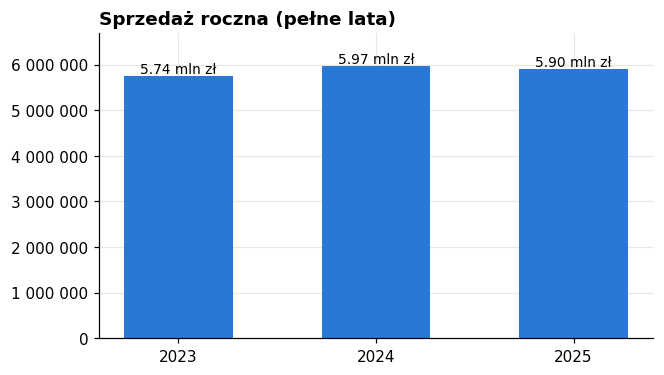

In [5]:
# Sprzedaż roczna, liczba dni handlowych i średnia na dzień handlowy
rok = dz.groupby("Rok").agg(
    Wartosc=("Wartosc", "sum"),
    DniHandlowe=("Handlowy", "sum"),
    Paragony=("Paragony", "sum"),
)
rok["SrednioNaDzien"] = rok["Wartosc"] / rok["DniHandlowe"]
rok["SredniParagon"] = rok["Wartosc"] / rok["Paragony"]
rok["ZmianaRR_%"] = rok.loc[[2023, 2024, 2025], "Wartosc"].pct_change() * 100   # tylko pełne lata
print(rok.round(1))

pelne = rok.loc[[2023, 2024, 2025]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(pelne.index.astype(str), pelne["Wartosc"], color=NIEB, width=0.55)
for x, v in zip(pelne.index.astype(str), pelne["Wartosc"]):
    ax.text(x, v, f"{v/1e6:.2f} mln zł", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(zl)
ax.set_title("Sprzedaż roczna (pełne lata)")
ax.set_ylim(0, pelne["Wartosc"].max() * 1.12)
plt.show()

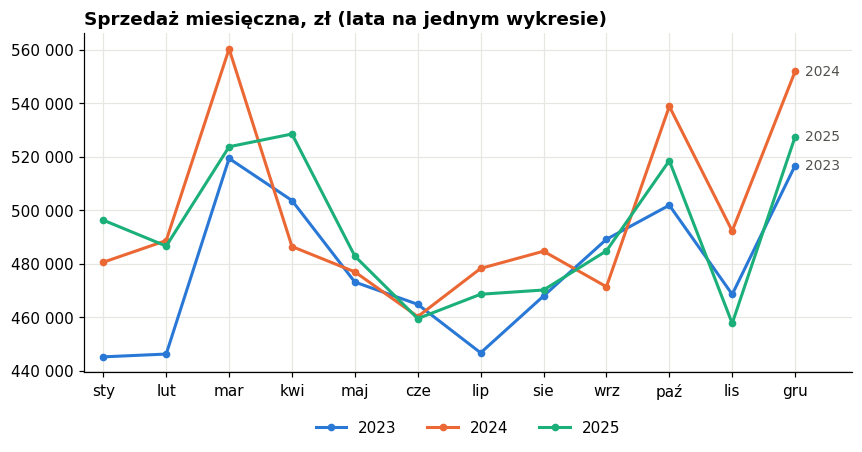

Rok      2023  2024  2025  2026
Miesiac                        
sty       NaN   7.9   3.3  -4.0
lut       NaN   9.5  -0.4   NaN
mar       NaN   7.9  -6.5   NaN
kwi       NaN  -3.4   8.6   NaN
maj       NaN   0.8   1.2   NaN
cze       NaN  -1.0  -0.2   NaN
lip       NaN   7.1  -2.0   NaN
sie       NaN   3.6  -3.0   NaN
wrz       NaN  -3.6   2.8   NaN
paź       NaN   7.4  -3.8   NaN
lis       NaN   5.1  -7.0   NaN
gru       NaN   6.8  -4.4   NaN


In [6]:
# Miesiące w kolejnych latach: ten sam miesiąc rok do roku
mies = dz.groupby(["Rok", "Miesiac"]).agg(Wartosc=("Wartosc", "sum"), DniHandlowe=("Handlowy", "sum"))
mies_suma = mies["Wartosc"].unstack(0)

fig, ax = plt.subplots(figsize=(9, 4))
for r in [2023, 2024, 2025]:
    ax.plot(MIES, mies_suma[r].values, marker="o", ms=4, lw=2, color=LATA_KOL[r], label=str(r))
    ax.text(11.15, mies_suma[r].iloc[-1], str(r), color="#52514e", va="center", fontsize=9)
ax.yaxis.set_major_formatter(zl)
ax.set_xlim(-0.3, 11.9)
ax.set_title("Sprzedaż miesięczna, zł (lata na jednym wykresie)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

# Zmiana rok do roku dla każdego miesiąca (procent)
zm = mies_suma.pct_change(axis=1) * 100
print(zm.round(1).rename(index=dict(zip(range(1, 13), MIES))))

## 3. Miesiąc (sezonowość)
Suma miesięczna zależy od liczby dni handlowych, więc porównujemy **średnią sprzedaż na dzień handlowy od poniedziałku do soboty**. Indeks 1,00 to średnia całego roku.

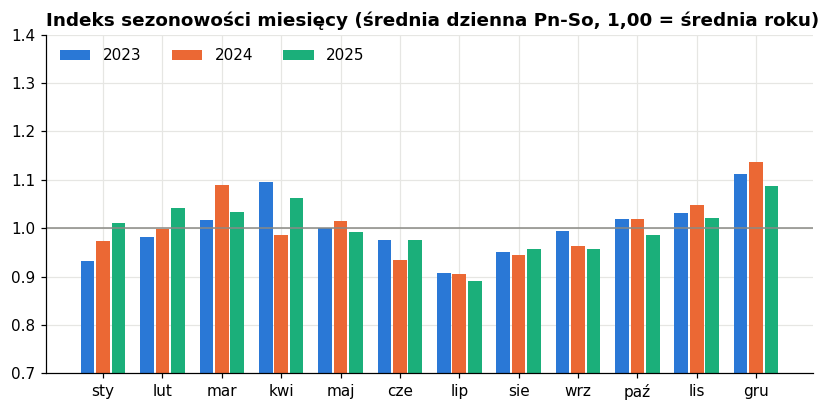

Rok      2023  2024  2025
Miesiac                  
sty      0.93  0.97  1.01
lut      0.98  1.00  1.04
mar      1.02  1.09  1.03
kwi      1.10  0.99  1.06
maj      1.00  1.02  0.99
cze      0.98  0.93  0.98
lip      0.91  0.91  0.89
sie      0.95  0.94  0.96
wrz      0.99  0.96  0.96
paź      1.02  1.02  0.99
lis      1.03  1.05  1.02
gru      1.11  1.14  1.09


In [7]:
# Indeks sezonowości miesięcy: średnia dzienna (Pn-So, dni ze sprzedażą) / średnia roku
pnso = dz[(dz["DzienTyg"] < 6) & dz["Handlowy"] & (dz["Rok"] <= 2025)]
sr_mies = pnso.groupby(["Rok", "Miesiac"])["Wartosc"].mean().unstack(0)
sr_rok = pnso.groupby("Rok")["Wartosc"].mean()
idx = sr_mies / sr_rok

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(12)
w = 0.26
for i, r in enumerate([2023, 2024, 2025]):
    ax.bar(x + (i - 1) * w, idx[r].values, width=w - 0.03, color=LATA_KOL[r], label=str(r))
ax.axhline(1, color=SZARY, lw=1)
ax.set_xticks(x); ax.set_xticklabels(MIES)
ax.set_ylim(0.7, 1.4)
ax.set_title("Indeks sezonowości miesięcy (średnia dzienna Pn-So, 1,00 = średnia roku)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()
print(idx.round(2).rename(index=dict(zip(range(1, 13), MIES))))

## 4. Dzień tygodnia

    DniHandlowe  SredniaWartosc  MedianaWartosc  SrednieParagony  \
Pn          153         18050.4         17690.0            843.6   
Wt          157         18354.4         17800.0            865.6   
Śr          155         18162.2         17802.9            857.9   
Cz          153         18539.1         18149.0            859.4   
Pt          156         21095.2         20591.7            922.7   
So          157         21635.6         21460.4            887.7   
Nd           21          5259.5          4519.6            238.3   

    SredniParagon  
Pn           21.4  
Wt           21.2  
Śr           21.1  
Cz           21.6  
Pt           22.8  
So           24.4  
Nd           21.7  


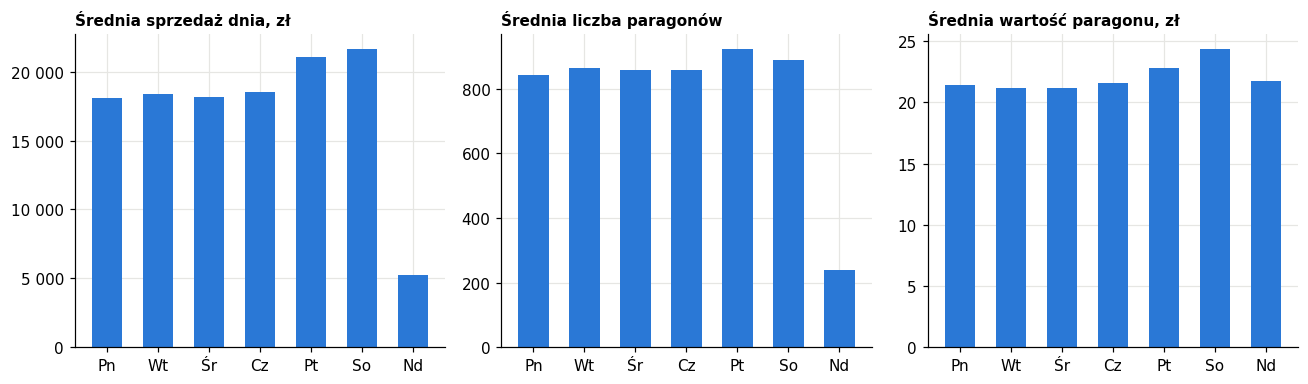

In [8]:
# Średnia sprzedaż, paragony i średni paragon wg dnia tygodnia (tylko dni handlowe)
hd = dz[dz["Handlowy"]]
dow = hd.groupby("DzienTyg").agg(
    DniHandlowe=("Wartosc", "size"),
    SredniaWartosc=("Wartosc", "mean"),
    MedianaWartosc=("Wartosc", "median"),
    SrednieParagony=("Paragony", "mean"),
    SredniParagon=("SredniParagon", "mean"),
)
dow.index = DNI
print(dow.round(1))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, kol_, tyt, fmt in [
    (axs[0], "SredniaWartosc", "Średnia sprzedaż dnia, zł", zl),
    (axs[1], "SrednieParagony", "Średnia liczba paragonów", zl),
    (axs[2], "SredniParagon", "Średnia wartość paragonu, zł", None),
]:
    ax.bar(dow.index, dow[kol_], color=NIEB, width=0.6)
    ax.set_title(tyt, fontsize=10)
    if fmt: ax.yaxis.set_major_formatter(fmt)
plt.tight_layout(); plt.show()

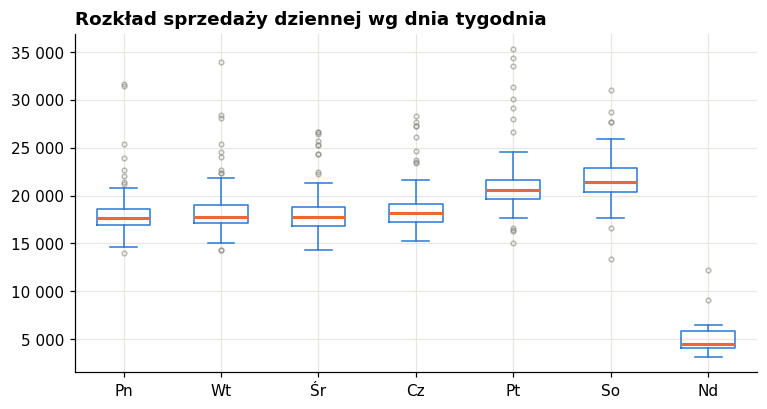

Rok     2023     2024     2025
Pn   17621.0  18361.0  18124.0
Wt   17763.0  18646.0  18711.0
Śr   17635.0  18446.0  18459.0
Cz   18175.0  18883.0  18669.0
Pt   20778.0  21323.0  21257.0
So   21539.0  21759.0  21640.0
Nd    4846.0   5734.0   5319.0


In [9]:
# Rozrzut sprzedaży dziennej w ciągu tygodnia (Pn-Nd, tylko dni ze sprzedażą)
dane_box = [hd.loc[hd["DzienTyg"] == i, "Wartosc"].values for i in range(7)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(dane_box, tick_labels=DNI, showfliers=True, widths=0.55,
           boxprops=dict(color=NIEB), medianprops=dict(color=POM, lw=2),
           whiskerprops=dict(color=NIEB), capprops=dict(color=NIEB),
           flierprops=dict(marker="o", ms=3, markeredgecolor=SZARY, alpha=0.6))
ax.yaxis.set_major_formatter(zl)
ax.set_title("Rozkład sprzedaży dziennej wg dnia tygodnia")
plt.show()

# Dzień tygodnia w kolejnych latach (średnia, tylko dni handlowe)
dow_rok = hd[hd["Rok"] <= 2025].groupby(["DzienTyg", "Rok"])["Wartosc"].mean().unstack()
dow_rok.index = DNI
print(dow_rok.round(0))

## 5. Święta
Sklep jest zamknięty w święta i większość niedziel. Sprawdzamy, jak sprzedaż zachowuje się **wokół** świąt (dni przed i po), na tle zwykłych dni. Punkt odniesienia dla każdego dnia to mediana sprzedaży **tego samego dnia tygodnia** w oknie ±6 tygodni, z pominięciem dni blisko świąt.

In [10]:
# Lista świąt w danych
print(swieta.to_string())

2023-01-01                                  Nowy Rok
2023-01-06                       Święto Trzech Króli
2023-04-09                     Niedziela Wielkanocna
2023-04-10                  Poniedziałek Wielkanocny
2023-05-01                          Święto Państwowe
2023-05-03            Święto Narodowe Trzeciego Maja
2023-05-28                           Zielone Świątki
2023-06-08                        Dzień Bożego Ciała
2023-08-15    Wniebowzięcie Najświętszej Marii Panny
2023-11-01           Uroczystość Wszystkich Świętych
2023-11-11            Narodowe Święto Niepodległości
2023-12-25          Boże Narodzenie (pierwszy dzień)
2023-12-26             Boże Narodzenie (drugi dzień)
2024-01-01                                  Nowy Rok
2024-01-06                       Święto Trzech Króli
2024-03-31                     Niedziela Wielkanocna
2024-04-01                  Poniedziałek Wielkanocny
2024-05-01                          Święto Państwowe
2024-05-03            Święto Narodowe Trzecieg

In [11]:
# Punkt odniesienia: mediana tego samego dnia tygodnia w oknie ±42 dni, bez dni z okolic świąt
BLISKO = 4   # dni od święta, które uznajemy za "okolice świąt"
blisko_swieta = np.zeros(len(dz), dtype=bool)
for d in swieta.index:
    blisko_swieta |= (np.abs((dz.index - d).days) <= BLISKO)
dz["BliskoSwieta"] = blisko_swieta

zwykle = dz[dz["Handlowy"] & ~dz["BliskoSwieta"] & (dz["DzienTyg"] < 6)]
def baza(data):
    okno = zwykle[(zwykle["DzienTyg"] == data.dayofweek) & ((zwykle.index - data).days.to_series(index=zwykle.index).abs() <= 42)]
    return okno["Wartosc"].median() if len(okno) >= 3 else np.nan

dz["Baza"] = [baza(d) if (h and w < 6) else np.nan for d, h, w in zip(dz.index, dz["Handlowy"], dz["DzienTyg"])]
dz["Wskaznik"] = dz["Wartosc"] / dz["Baza"]       # 1,00 = tyle co zwykle
print(dz.loc[dz["Wskaznik"].notna(), "Wskaznik"].describe().round(2))

count    931.00
mean       1.02
std        0.12
min        0.58
25%        0.97
50%        1.00
75%        1.05
max        1.95
Name: Wskaznik, dtype: float64


    Boże Narodzenie (25.12)  Wielkanoc (niedziela)  \
-7                     1.20                    NaN   
-6                     1.18                   1.10   
-5                     1.15                   1.25   
-4                     1.24                   1.31   
-3                     1.63                   1.50   
-2                     1.69                   1.62   
-1                     0.90                   0.93   
 0                      NaN                    NaN   
 1                      NaN                    NaN   
 2                     0.72                   0.82   
 3                     0.87                   0.94   

    Wszystkich Świętych (1.11)  Nowy Rok (1.01)  Boże Ciało  3 Maja  
-7                        1.02              NaN        1.06    0.99  
-6                        0.99              NaN        1.01    1.06  
-5                        1.05             0.72        1.11    1.03  
-4                        1.05             0.87         NaN    1.09  
-

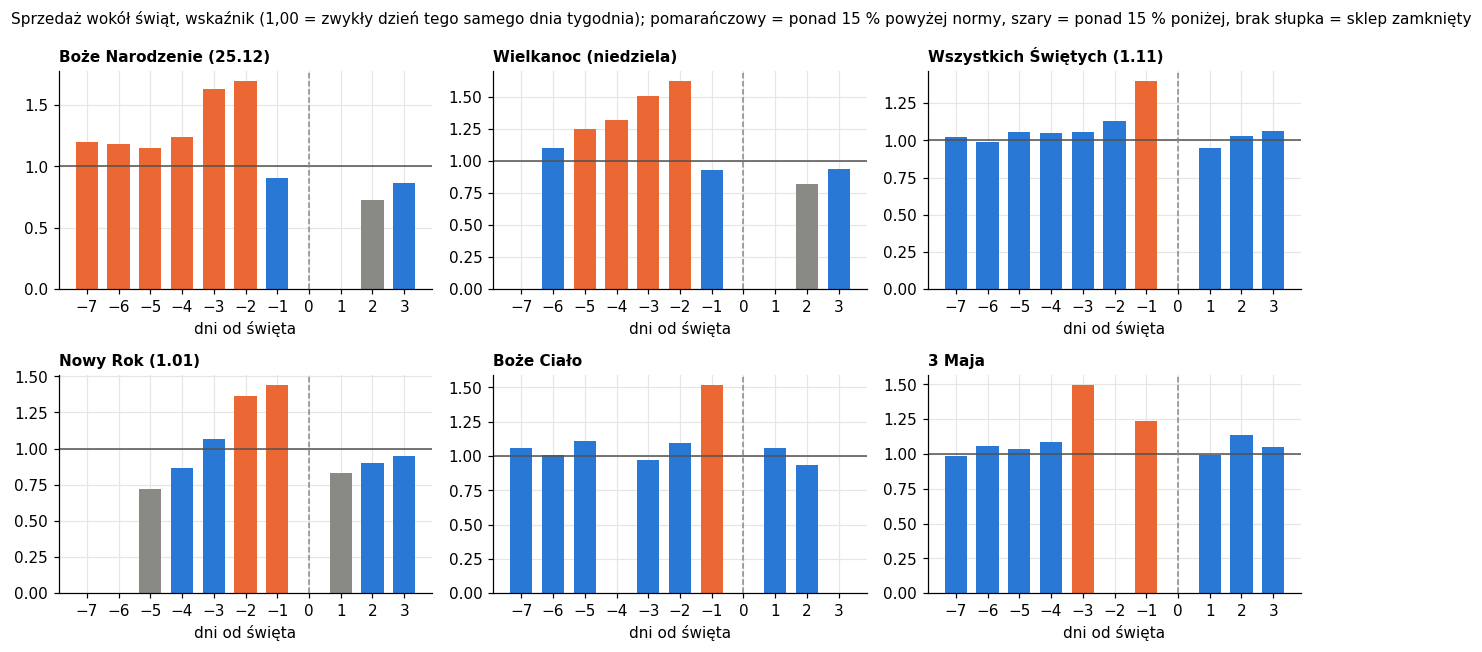

In [12]:
# Profil sprzedaży wokół wybranych świąt: wskaźnik dla dni od -7 do +3 względem święta
lata = range(dz.index.year.min(), dz.index.year.max() + 1)
WYBRANE = {                                   # daty liczymy wprost (nie po nazwach), więc działa w każdym języku biblioteki
    "Boże Narodzenie (25.12)": [pd.Timestamp(y, 12, 25) for y in lata],
    "Wielkanoc (niedziela)": [pd.Timestamp(easter(y)) for y in lata],
    "Wszystkich Świętych (1.11)": [pd.Timestamp(y, 11, 1) for y in lata],
    "Nowy Rok (1.01)": [pd.Timestamp(y, 1, 1) for y in lata],
    "Boże Ciało": [pd.Timestamp(easter(y)) + pd.Timedelta(days=60) for y in lata],
    "3 Maja": [pd.Timestamp(y, 5, 3) for y in lata],
}
OFFS = list(range(-7, 4))
profile = {}
for nazwa, daty in WYBRANE.items():
    wiersze = []
    for d in daty:
        w = {o: dz["Wskaznik"].get(d + pd.Timedelta(days=o), np.nan) for o in OFFS}
        wiersze.append(w)
    profile[nazwa] = pd.DataFrame(wiersze).mean()
prof = pd.DataFrame(profile)
print(prof.round(2))

fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharey=False)
for ax, nazwa in zip(axs.ravel(), prof.columns):
    s = prof[nazwa]
    kol_ = [POM if v > 1.15 else (NIEB if np.isnan(v) or v >= 0.85 else SZARY) for v in s.values]
    ax.bar(s.index, s.fillna(0).values, color=kol_, width=0.7)
    ax.axhline(1, color="#52514e", lw=1)
    ax.axvline(0, color=SZARY, lw=1, ls="--")
    ax.set_title(nazwa, fontsize=10)
    ax.set_xticks(OFFS)
    ax.set_xlabel("dni od święta")
plt.suptitle("Sprzedaż wokół świąt, wskaźnik (1,00 = zwykły dzień tego samego dnia tygodnia); pomarańczowy = ponad 15 % powyżej normy, szary = ponad 15 % poniżej, brak słupka = sklep zamknięty", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

In [13]:
# Najlepsze i najsłabsze dni w całych danych (dni handlowe Pn-So), z opisem święta
top = dz[dz["Handlowy"] & (dz["DzienTyg"] < 6)].sort_values("Wartosc")
def opisz(d):
    # najbliższe święto, w odległości do 7 dni
    odl = (swieta.index - d).days
    i = int(np.argmin(np.abs(odl)))
    return f"{swieta.iloc[i]} ({int(odl[i]):+d} dni)" if abs(odl[i]) <= 7 else ""
for tytul, czesc in [("Najwyższa sprzedaż", top.tail(8)[::-1]), ("Najniższa sprzedaż (Pn-So)", top.head(8))]:
    t = czesc[["Wartosc", "Paragony"]].copy()
    t["DzienTyg"] = [DNI[i] for i in czesc["DzienTyg"]]
    t["Okolice"] = [opisz(d) for d in czesc.index]
    print(tytul); print(t.round(0).to_string()); print()

Najwyższa sprzedaż
            Wartosc  Paragony DzienTyg                                    Okolice
Data                                                                             
2023-04-07  35314.0      1300       Pt             Niedziela Wielkanocna (+2 dni)
2024-03-29  34377.0      1267       Pt             Niedziela Wielkanocna (+2 dni)
2025-12-23  33943.0      1307       Wt         Wigilia Bożego Narodzenia (+1 dni)
2025-04-18  33492.0      1252       Pt             Niedziela Wielkanocna (+2 dni)
2025-12-22  31674.0      1218       Pn         Wigilia Bożego Narodzenia (+2 dni)
2024-12-23  31434.0      1165       Pn  Boże Narodzenie (pierwszy dzień) (+2 dni)
2023-11-10  31378.0      1201       Pt    Narodowe Święto Niepodległości (+1 dni)
2023-12-23  30974.0      1083       So  Boże Narodzenie (pierwszy dzień) (+2 dni)

Najniższa sprzedaż (Pn-So)
            Wartosc  Paragony DzienTyg                                 Okolice
Data                                                  

In [14]:
# Niedziele handlowe: czy sprzedaż odbiega od zwykłej niedzieli handlowej i od soboty?
nd = dz[(dz["DzienTyg"] == 6) & dz["Handlowy"]]
sob_przed = [dz["Wartosc"].get(d - pd.Timedelta(days=1), np.nan) for d in nd.index]
t = pd.DataFrame({"Wartosc": nd["Wartosc"].round(0), "SobotaPrzed": np.round(sob_przed, 0), "Okolice": [opisz(d) for d in nd.index]})
t["Nd/So"] = (t["Wartosc"] / t["SobotaPrzed"]).round(2)
print(t.to_string())

            Wartosc  SobotaPrzed                                    Okolice  Nd/So
Data                                                                              
2023-01-29   4181.0      21522.0                                              0.19
2023-04-02   5780.0      23365.0             Niedziela Wielkanocna (+7 dni)   0.25
2023-06-25   3151.0      19363.0                                              0.16
2023-12-10   4602.0      22917.0                                              0.20
2023-12-17   6518.0      22453.0                                              0.29
2024-01-28   4297.0      20833.0                                              0.21
2024-03-24   6286.0      24109.0             Niedziela Wielkanocna (+7 dni)   0.26
2024-04-28   4032.0      21850.0                  Święto Państwowe (+3 dni)   0.18
2024-06-30   3543.0      20479.0                                              0.17
2024-08-25   3996.0      19159.0                                              0.21
2024

## 6. Szeregi czasowe
Szereg sprzedaży dziennej Pn-So (niedziele pomijamy, bo prawie zawsze są zamknięte). Święta w Pn-So nie mają sprzedaży, więc na potrzeby dekompozycji uzupełniamy je interpolacją (to tylko kilkadziesiąt dni). Wymaga biblioteki `statsmodels`.

Dni Pn-So w szeregu: 966, uzupełnionych (święta): 35


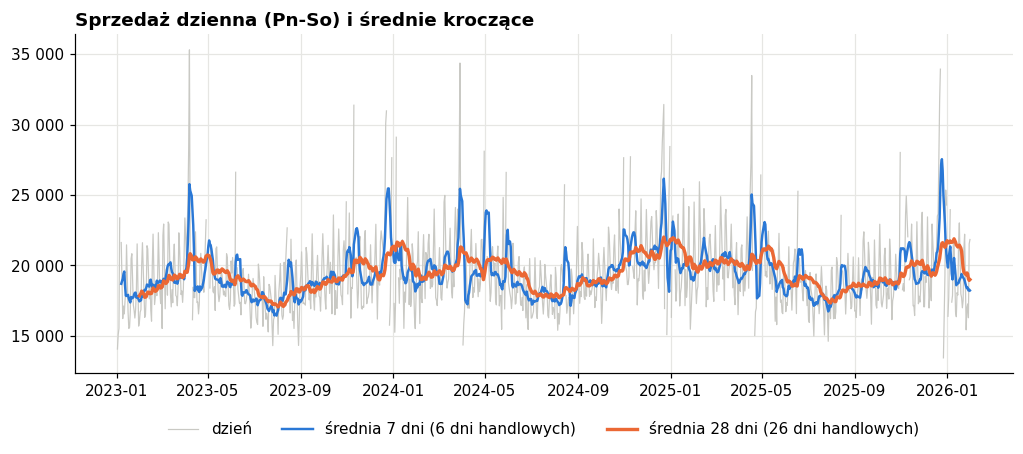

In [15]:
# Szereg Pn-So: święta (brak sprzedaży) uzupełnione interpolacją, tylko do dekompozycji i ACF
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

ts = dz.loc[dz["DzienTyg"] < 6, "Wartosc"].astype(float)
ts[~dz.loc[ts.index, "Handlowy"]] = np.nan
n_braki = int(ts.isna().sum())
ts_i = ts.interpolate(limit_direction="both")
print(f"Dni Pn-So w szeregu: {len(ts_i)}, uzupełnionych (święta): {n_braki}")

# Średnie kroczące (7 i 28 dni handlowych) na tle surowych danych
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ts.index, ts.values, color="#c9c9c4", lw=0.8, label="dzień")
ax.plot(ts.index, ts_i.rolling(6, min_periods=6).mean(), color=NIEB, lw=1.6, label="średnia 7 dni (6 dni handlowych)")
ax.plot(ts.index, ts_i.rolling(26, min_periods=26).mean(), color=POM, lw=2.2, label="średnia 28 dni (26 dni handlowych)")
ax.yaxis.set_major_formatter(zl)
ax.set_title("Sprzedaż dzienna (Pn-So) i średnie kroczące")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

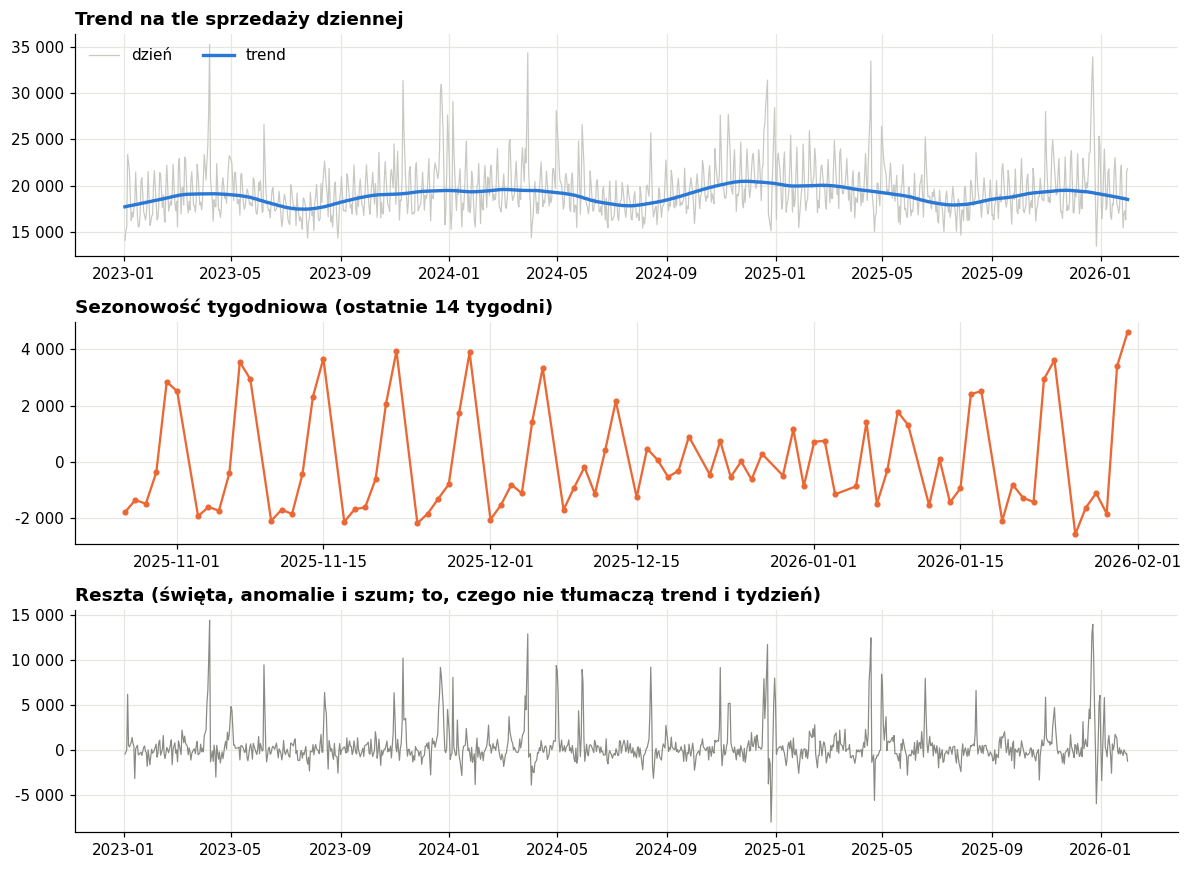

Udział w wariancji szeregu, %:
Trend       6.7
Tydzien    35.3
Reszta     57.5
Reszta: 83 % sumy kwadratów pochodzi z dni w okolicach świąt (±4 dni), a to 24 % dni
Wzorzec tygodniowy (średnia składnika wg dnia tygodnia), zł:
Data
Pn   -1134.0
Wt    -876.0
Śr   -1372.0
Cz    -889.0
Pt    1753.0
So    2517.0


In [16]:
# Dekompozycja STL: trend (z wolnymi zmianami rocznymi) + sezonowość tygodniowa (6 dni) + reszta
# Sezonowości rocznej nie wydzielamy: przy 3 latach danych byłyby tylko 3 powtórzenia roku i model by się "przeuczył".
y = pd.Series(ts_i.values)                       # indeks całkowity: statsmodels wymaga regularnych kroków
res = STL(y, period=6, seasonal=7, trend=79, robust=True).fit()   # trend=79 dni handlowych ≈ 13 tygodni
dek = pd.DataFrame({
    "Obserwacja": ts_i.values,
    "Trend": res.trend.values,
    "Tydzien": res.seasonal.values,
    "Reszta": res.resid.values,
}, index=ts_i.index)

fig, axs = plt.subplots(3, 1, figsize=(11, 8))
axs[0].plot(dek.index, dek["Obserwacja"], color="#c9c9c4", lw=0.8, label="dzień")
axs[0].plot(dek.index, dek["Trend"], color=NIEB, lw=2.2, label="trend")
axs[0].set_title("Trend na tle sprzedaży dziennej")
axs[0].legend(frameon=False, ncol=2, loc="upper left")
axs[1].plot(dek.index[-84:], dek["Tydzien"].iloc[-84:], color=POM, lw=1.5, marker="o", ms=3)
axs[1].set_title("Sezonowość tygodniowa (ostatnie 14 tygodni)")
axs[2].plot(dek.index, dek["Reszta"], color=SZARY, lw=0.8)
axs[2].set_title("Reszta (święta, anomalie i szum; to, czego nie tłumaczą trend i tydzień)")
for ax in axs: ax.yaxis.set_major_formatter(zl)
plt.tight_layout(); plt.show()

# Ile zmienności tłumaczy każdy składnik (wariancja składnika / wariancja szeregu; nie sumują się do 100 %)
udzial = (dek[["Trend", "Tydzien", "Reszta"]].var() / dek["Obserwacja"].var() * 100).round(1)
print("Udział w wariancji szeregu, %:"); print(udzial.to_string())
bl = dz.loc[dek.index, "BliskoSwieta"].values
print(f"Reszta: {(dek['Reszta'][bl]**2).sum() / (dek['Reszta']**2).sum() * 100:.0f} % sumy kwadratów pochodzi z dni w okolicach świąt (±4 dni), a to {bl.mean()*100:.0f} % dni")
print("Wzorzec tygodniowy (średnia składnika wg dnia tygodnia), zł:")
print(dek.groupby(dek.index.dayofweek)["Tydzien"].mean().round(0).rename(index=dict(enumerate(DNI))).to_string())

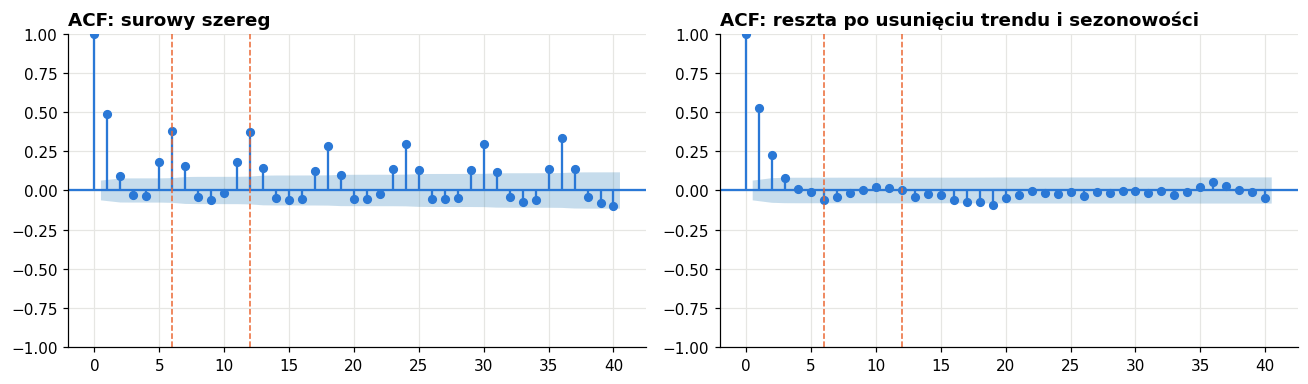

In [17]:
# Autokorelacja: surowy szereg i reszta po dekompozycji (kroki = dni handlowe Pn-So, tydzień = lag 6)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(ts_i.values, lags=40, ax=axs[0], color=NIEB, vlines_kwargs={"colors": NIEB})
axs[0].set_title("ACF: surowy szereg")
plot_acf(dek["Reszta"].values, lags=40, ax=axs[1], color=NIEB, vlines_kwargs={"colors": NIEB})
axs[1].set_title("ACF: reszta po usunięciu trendu i sezonowości")
for ax in axs:
    ax.axvline(6, color=POM, ls="--", lw=1); ax.axvline(12, color=POM, ls="--", lw=1)
plt.tight_layout(); plt.show()

### Baseline (punkt odniesienia dla modelu)
Prosta prognoza „ten sam dzień tygodnia w poprzednich tygodniach”, liczona tylko z przeszłości. Ostatnie 13 tygodni danych to zbiór testowy. Każdy model uczący się będzie musiał dać lepszy wynik niż te dwie metody.

Zbiór testowy: 2025-11-03 … 2026-01-31, dni: 66

wszystkie dni (dni: 66)
        Tydzien_temu  Srednia_4_tygodni
MAE_zl        2392.0             2362.9
WAPE_%          11.9               11.8
MAPE_%          11.7               11.7

poza okolicami świąt (dni: 46)
        Tydzien_temu  Srednia_4_tygodni
MAE_zl        1276.4             1905.1
WAPE_%           6.6                9.9
MAPE_%           6.8               10.2

okolice świąt (dni: 20)
        Tydzien_temu  Srednia_4_tygodni
MAE_zl        4957.7             3415.7
WAPE_%          22.9               15.8
MAPE_%          22.8               15.1


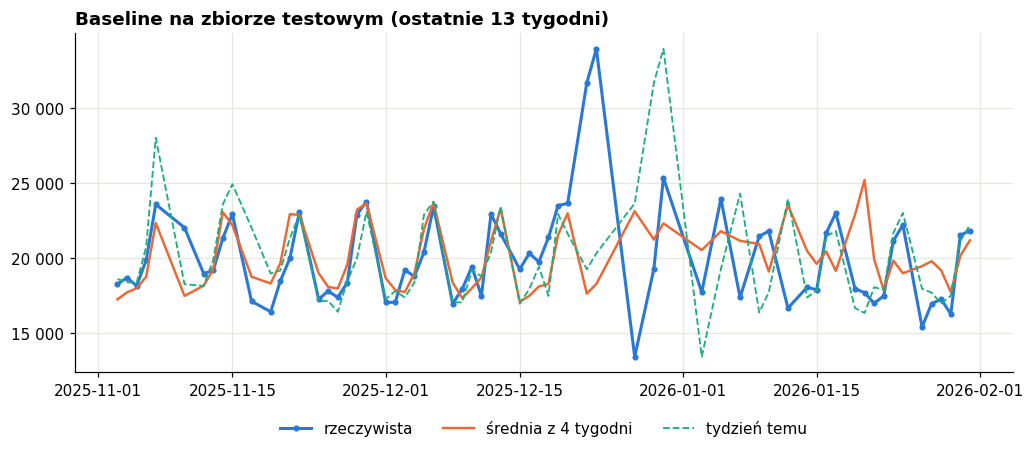

In [18]:
# Dwa proste baseline'y: (1) dokładnie tydzień wcześniej, (2) średnia z 4 poprzednich tygodni tego dnia tygodnia
s_h = dz["Wartosc"].where(dz["Handlowy"])               # dni zamknięte = brak (nie zero)
pred_t1 = s_h.shift(7)
pred_t4 = pd.concat([s_h.shift(7 * k) for k in range(1, 5)], axis=1).mean(axis=1)

TEST_DNI = 91
koniec = dz.index.max()
test_idx = dz.index[(dz.index > koniec - pd.Timedelta(days=TEST_DNI)) & dz["Handlowy"] & (dz["DzienTyg"] < 6)]
tab = pd.DataFrame({"Rzeczywista": s_h.loc[test_idx], "Tydzien_temu": pred_t1.loc[test_idx], "Srednia_4_tygodni": pred_t4.loc[test_idx]}).dropna()
tab["Okolice_swiat"] = dz.loc[tab.index, "BliskoSwieta"]

def metryki(t, kol):
    e = t[kol] - t["Rzeczywista"]
    return pd.Series({"MAE_zl": e.abs().mean(), "WAPE_%": e.abs().sum() / t["Rzeczywista"].sum() * 100, "MAPE_%": (e.abs() / t["Rzeczywista"]).mean() * 100})

print(f"Zbiór testowy: {tab.index.min().date()} … {tab.index.max().date()}, dni: {len(tab)}")
for nazwa, t in [("wszystkie dni", tab), ("poza okolicami świąt", tab[~tab["Okolice_swiat"]]), ("okolice świąt", tab[tab["Okolice_swiat"]])]:
    print(f"\n{nazwa} (dni: {len(t)})")
    print(pd.DataFrame({k: metryki(t, k) for k in ["Tydzien_temu", "Srednia_4_tygodni"]}).round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tab.index, tab["Rzeczywista"], color=NIEB, lw=2, marker="o", ms=3, label="rzeczywista")
ax.plot(tab.index, tab["Srednia_4_tygodni"], color=POM, lw=1.6, label="średnia z 4 tygodni")
ax.plot(tab.index, tab["Tydzien_temu"], color=MOR, lw=1.2, ls="--", label="tydzień temu")
ax.yaxis.set_major_formatter(zl)
ax.set_title("Baseline na zbiorze testowym (ostatnie 13 tygodni)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

In [19]:
# Anomalie: dni z dużą resztą po dekompozycji (modyfikowany z-score na MAD, próg 3,5)
r = dek["Reszta"]
mad = (r - r.median()).abs().median()
z = 0.6745 * (r - r.median()) / mad
anom = dek.loc[z.abs() > 3.5, ["Obserwacja", "Reszta"]].copy()
anom["z"] = z[anom.index].round(1)
anom["DzienTyg"] = [DNI[i] for i in anom.index.dayofweek]
anom["Uzupelniony"] = ts.isna().reindex(anom.index)
anom = anom[~anom["Uzupelniony"]].drop(columns="Uzupelniony")   # dni uzupełnione interpolacją nie są prawdziwymi danymi
def blisko(d):
    odl = (swieta.index - d).days
    i = int(np.argmin(np.abs(odl)))
    return f"{swieta.iloc[i]} ({int(odl[i]):+d} dni)" if abs(odl[i]) <= 7 else ""
anom["Okolice"] = [blisko(d) for d in anom.index]
print(f"Dni z |z| > 3,5 (bez uzupełnionych): {len(anom)} z {len(r) - n_braki}")
print(anom.sort_values("z").round(0).to_string())

Dni z |z| > 3,5 (bez uzupełnionych): 69 z 931
            Obserwacja   Reszta     z DzienTyg                                          Okolice
Data                                                                                           
2024-12-27     15077.0  -8061.0  -9.0       Pt           Boże Narodzenie (drugi dzień) (-1 dni)
2025-12-27     13421.0  -6004.0  -7.0       So           Boże Narodzenie (drugi dzień) (-1 dni)
2025-04-22     15014.0  -5632.0  -7.0       Wt                Poniedziałek Wielkanocny (-1 dni)
2024-12-28     19278.0  -4123.0  -5.0       So           Boże Narodzenie (drugi dzień) (-2 dni)
2024-04-02     14339.0  -3921.0  -5.0       Wt                Poniedziałek Wielkanocny (-1 dni)
2024-12-24     16926.0  -3797.0  -4.0       Wt        Boże Narodzenie (pierwszy dzień) (+1 dni)
2024-01-30     15501.0  -3860.0  -4.0       Wt                                                 
2025-10-24     18792.0  -3358.0  -4.0       Pt                                            

## 7. Cechy dla modelu: przygotowanie
Budujemy tu tylko to, co model będzie mógł znać **w chwili prognozy**, czyli bez wycieku przyszłości (zapis do jednego pliku jest w sekcji 15, po części o klasach):
- cechy kalendarzowe i świąteczne (tabela `kal`), także na dni po końcu danych (do końca roku 2026), bo święta znamy z góry,
- sprzedaż dzienna sklepu (cel prognozy) i opóźnienia liczone wyłącznie z przeszłości (tabela `dz_model`),
- `baseline_metryki.csv`: wyniki prostych metod, które model musi pobić (to raport, nie cechy).

Celowo **nie zapisujemy** trendu, reszty z STL, wskaźnika wokół świąt ani indeksu sezonowości: liczone były na całych danych (także na przyszłości względem dnia prognozy), więc użyte jako cechy dałyby zawyżone wyniki na testach.

In [20]:
# Cechy kalendarzowe i świąteczne (znane z góry, także dla dni po końcu danych)
OSTATNI_DZIEN = pd.Timestamp("2026-12-31")
dni = pd.date_range("2023-01-01", OSTATNI_DZIEN, freq="D")   # od początku kalendarza (1 stycznia 2023)
sw_all = swieta_polska(range(dni.year.min(), dni.year.max() + 1))
sw_idx = pd.DatetimeIndex(sorted(pd.Timestamp(d) for d in sw_all))
sw_nazwa = {pd.Timestamp(d): n for d, n in sw_all.items()}
wielkanoc = {y: pd.Timestamp(easter(y)) for y in dni.year.unique()}
boze_narodzenie = {y: pd.Timestamp(y, 12, 25) for y in dni.year.unique()}

kal = pd.DataFrame(index=dni); kal.index.name = "Data"
kal["Rok"] = dni.year.astype("int16")
kal["Miesiac"] = dni.month.astype("int8")
kal["DzienMiesiaca"] = dni.day.astype("int8")
kal["DzienTyg"] = dni.dayofweek.astype("int8")
kal["TydzienRoku"] = dni.isocalendar().week.values.astype("int8")
kal["DzienRoku"] = dni.dayofyear.astype("int16")
kal["CzySwieto"] = dni.isin(sw_idx).astype("int8")
kal["NazwaSwieta"] = pd.Series(dni.map(lambda d: sw_nazwa.get(d, "")), index=dni)

# odległość (w dniach) do następnego i od poprzedniego święta (ograniczona do 30)
poz = np.searchsorted(sw_idx.values, dni.values)                       # indeks następnego święta (>= data)
nast = sw_idx.values[np.minimum(poz, len(sw_idx) - 1)]
poprz = sw_idx.values[np.maximum(poz - 1, 0)]
kal["DniDoSwieta"] = np.clip((nast - dni.values).astype("timedelta64[D]").astype(int), 0, 30).astype("int8")
kal["DniOdSwieta"] = np.clip((dni.values - poprz).astype("timedelta64[D]").astype(int), 0, 30).astype("int8")
kal["DzienPrzedSwietem"] = dni.map(lambda d: int((d + pd.Timedelta(days=1)) in sw_nazwa)).astype("int8")
kal["DzienPoSwiecie"] = dni.map(lambda d: int((d - pd.Timedelta(days=1)) in sw_nazwa)).astype("int8")
kal["BliskoSwieta"] = ((kal["DniDoSwieta"] <= 4) | (kal["DniOdSwieta"] <= 4)).astype("int8")

# święta ruchome i duże sezony: dni do Wielkanocy i do Bożego Narodzenia (ze znakiem, ograniczone)
kal["DniDoWielkanocy"] = np.clip([(wielkanoc[d.year] - d).days for d in dni], -30, 30).astype("int8")
kal["DniDoBozegoNarodzenia"] = np.clip([(boze_narodzenie[d.year] - d).days for d in dni], -14, 60).astype("int8")

# czy sklep otwarty: z danych dla dni do końca danych (dni po końcu danych = brak informacji)
ost_dane = dz.index.max()
otwarty = dz["Handlowy"].astype("int8").reindex(dni).fillna(0)   # dni bez wiersza w danych (np. 1 stycznia) = zamknięte
kal["CzyOtwarty"] = otwarty.where(dni <= ost_dane)                       # NaN dla przyszłości
# niedziela handlowa z kalendarza w pliku (z przepisów); NaN po końcu danych, bo listy na 2026 plik nie zawiera
kal["CzyNiedzielaHandlowa"] = kal_pq["CzyNiedzielaHandlowa"].reindex(dni).astype("float").where(dni <= ost_dane)
kal["CzyDlugiWeekend"] = kal_pq["CzyDlugiWeekend"].reindex(dni).astype("float").where(dni <= ost_dane)
kal["CzyOtwartyRegula"] = ((kal["DzienTyg"] < 6) & (kal["CzySwieto"] == 0)).astype("int8")   # reguła: Pn-So poza świętami

print(kal.shape, kal.index.min().date(), kal.index.max().date())
print(kal.loc["2025-04-16":"2025-04-22"].drop(columns=["Rok", "DzienRoku", "TydzienRoku"]).to_string())

(1461, 19) 2023-01-01 2026-12-31
            Miesiac  DzienMiesiaca  DzienTyg  CzySwieto               NazwaSwieta  DniDoSwieta  DniOdSwieta  DzienPrzedSwietem  DzienPoSwiecie  BliskoSwieta  DniDoWielkanocy  DniDoBozegoNarodzenia  CzyOtwarty  CzyNiedzielaHandlowa  CzyDlugiWeekend  CzyOtwartyRegula
Data                                                                                                                                                                                                                                                                     
2025-04-16        4             16         2          0                                      4           30                  0               0             1                4                     60         1.0                   0.0              0.0                 1
2025-04-17        4             17         3          0                                      3           30                  0               0             1             

In [21]:
# Sprzedaż dzienna sklepu (cel prognozy) + opóźnienia liczone tylko z przeszłości
dz_model = dz[["Wartosc", "Sztuki", "Paragony", "Pozycje", "SredniParagon", "Handlowy"]].copy()
dz_model["Handlowy"] = dz_model["Handlowy"].astype("int8")
s_h = dz["Wartosc"].where(dz["Handlowy"])               # dni zamknięte = brak, nie zero
for k in (1, 2, 3, 4):
    dz_model[f"Wartosc_lag{7 * k}"] = s_h.shift(7 * k)                       # ten sam dzień tygodnia k tygodni wcześniej
dz_model["Wartosc_sr4tyg"] = dz_model[[f"Wartosc_lag{7 * k}" for k in (1, 2, 3, 4)]].mean(axis=1)

os.makedirs("dane/interim", exist_ok=True)

# Metryki baseline'u (zbiór testowy z sekcji 6) jako poprzeczka dla modelu
wiersze = []
for nazwa, t in [("wszystkie dni", tab), ("poza okolicami świąt", tab[~tab["Okolice_swiat"]]), ("okolice świąt", tab[tab["Okolice_swiat"]])]:
    for metoda in ["Tydzien_temu", "Srednia_4_tygodni"]:
        m = metryki(t, metoda)
        wiersze.append({"zakres": nazwa, "metoda": metoda, "dni": len(t), **m.round(2).to_dict(),
                        "test_od": str(tab.index.min().date()), "test_do": str(tab.index.max().date())})
pd.DataFrame(wiersze).to_csv("dane/interim/baseline_metryki.csv", index=False)

print("Przygotowano: kal", kal.shape, "| dz_model", dz_model.shape, "| zapisano baseline_metryki.csv", len(wiersze), "wierszy")
print(dz_model.tail(4).round(1).to_string())

Przygotowano: kal (1461, 19) | dz_model (1126, 11) | zapisano baseline_metryki.csv 6 wierszy
            Wartosc  Sztuki  Paragony  Pozycje  SredniParagon  Handlowy  Wartosc_lag7  Wartosc_lag14  Wartosc_lag21  Wartosc_lag28  Wartosc_sr4tyg
Data                                                                                                                                              
2026-01-28  17254.7  3378.7       848     3281           20.3         1       16979.9        18057.6        17380.6        24290.9         19177.2
2026-01-29  16271.6  3256.9       736     3124           22.1         1       17492.7        17888.7        17859.3            NaN         17746.9
2026-01-30  21523.1  4051.1       860     3842           25.0         1       21147.2        21670.6        21457.7        16374.7         20162.6
2026-01-31  21833.5  4235.9       801     4037           27.3         1       22209.5        23013.1        21799.4        17727.7         21187.4


# Część II. Sprzedaż i sezonowość w podziale na klasy A/B/C/D
Czy towary klas A, B, C i D sprzedają się w czasie inaczej: dzień tygodnia, miesiąc, święta? Klasy pochodzą z kolumny `KategoriaABCD` (martwe towary dostają D). Sekcje numerujemy dalej (8–15), a importy i ustawienia wykresów z części I są wspólne.

**Uwaga o klasie D.** D oznacza towar, który przestał się sprzedawać do końca danych. Klasa jest więc wyznaczona na podstawie przyszłości (względem większości dni), co jest dobre do opisu, ale ryzykowne jako cecha modelu (wyciek przyszłości). Wrócimy do tego w ostatniej sekcji.

In [22]:
# Stałe części II: klasy i ich kolory (ten sam kolor klasy na każdym wykresie)
KLASY = ["A", "B", "C", "D"]
KOL = {"A": NIEB, "B": POM, "C": MOR, "D": SZARY}

In [23]:
# Wczytanie sprzedaży z klasą towaru
PLIK = "dane/interim/fact_inka_final.parquet"
kol = ["SKU", "Data", "DokId", "TypDok", "IloscPlus", "Wartosc", "KategoriaABCD"]
df = pd.read_parquet(PLIK, columns=kol)
klasa_tow = df.groupby("SKU", observed=True)["KategoriaABCD"].first()          # jedna klasa na towar
assert df.groupby("SKU", observed=True)["KategoriaABCD"].nunique().max() == 1, "klasa towaru nie jest stała"

s = df[(df["DokId"] != -1) & (df["TypDok"] == 21)].copy()
s["Klasa"] = pd.Categorical(s["KategoriaABCD"], categories=KLASY)
del df
print(f"Wierszy sprzedaży: {len(s):,}".replace(",", " "), "| zakres:", s["Data"].min().date(), "…", s["Data"].max().date())
print("Wiersze bez klasy:", int(s["Klasa"].isna().sum()))

Wierszy sprzedaży: 3 373 975 | zakres: 2023-01-02 … 2026-01-31
Wiersze bez klasy: 0


## 8. Skład klas
Ile jest towarów w każdej klasie, jaką część wartości i sztuk sprzedają.

   Towary  TowarySprzedane     Wartosc     Sztuki  Paragony  Towary_%  Wartosc_%  SrWartoscNaTowar
A    2727             2727  14331710.0  2783018.8    754705      21.8       79.2            5255.5
B    2701             2701   2434093.4   576830.0    302509      21.6       13.5             901.2
C    3955             3955    628340.3   135822.7     89393      31.7        3.5             158.9
D    3098             3098    698938.3   137574.6     84643      24.8        3.9             225.6


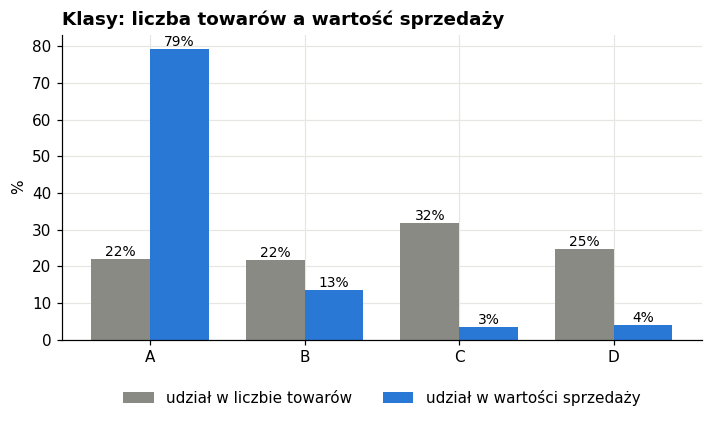

In [24]:
# Towary, wartość i sztuki wg klasy
skl = pd.DataFrame({
    "Towary": klasa_tow.value_counts().reindex(KLASY),
    "TowarySprzedane": s.groupby("Klasa", observed=False)["SKU"].nunique(),
    "Wartosc": s.groupby("Klasa", observed=False)["Wartosc"].sum(),
    "Sztuki": s.groupby("Klasa", observed=False)["IloscPlus"].sum(),
    "Paragony": s.groupby("Klasa", observed=False)["DokId"].nunique(),
})
skl["Towary_%"] = skl["Towary"] / skl["Towary"].sum() * 100
skl["Wartosc_%"] = skl["Wartosc"] / skl["Wartosc"].sum() * 100
skl["SrWartoscNaTowar"] = skl["Wartosc"] / skl["TowarySprzedane"]
print(skl.round(1).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(4); w = 0.38
ax.bar(x - w/2, skl["Towary_%"], w, color=SZARY, label="udział w liczbie towarów")
ax.bar(x + w/2, skl["Wartosc_%"], w, color=NIEB, label="udział w wartości sprzedaży")
for xi, a, b in zip(x, skl["Towary_%"], skl["Wartosc_%"]):
    ax.text(xi - w/2, a, f"{a:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.text(xi + w/2, b, f"{b:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, KLASY); ax.set_ylabel("%")
ax.set_title("Klasy: liczba towarów a wartość sprzedaży")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

## 9. Klasy w czasie
Dla każdej klasy sprzedaż miesięczna. Jeśli D jest „historyczne”, jego udział powinien spadać z czasem.

Dni: 1126 | dni handlowe: 952


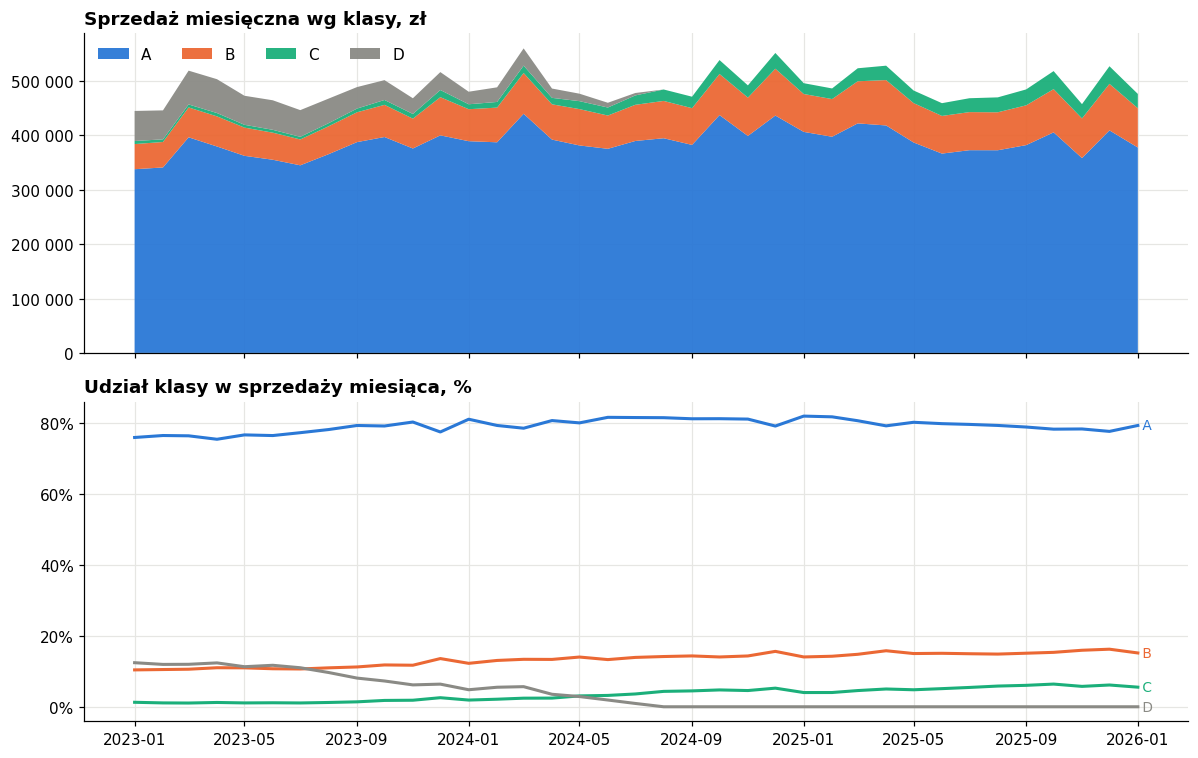

Klasa          A         B         C         D
Rok                                           
2023   4445687.0  643340.0   80589.0  573080.0
2024   4807483.0  825694.0  210786.0  125858.0
2025   4700683.0  892783.0  310622.0       0.0

Klasa     A     B    C     D
Rok                         
2023   77.4  11.2  1.4  10.0
2024   80.5  13.8  3.5   2.1
2025   79.6  15.1  5.3   0.0


In [25]:
# Tabela dzienna: wartość, sztuki, paragony i liczba różnych towarów wg klasy na pełnym kalendarzu
kalendarz = pd.date_range(s["Data"].min(), s["Data"].max(), freq="D")
g = s.groupby(["Data", "Klasa"], observed=False)
dk = pd.DataFrame({
    "Wartosc": g["Wartosc"].sum(), "Sztuki": g["IloscPlus"].sum(),
    "Paragony": g["DokId"].nunique(), "LiczbaTowarow": g["SKU"].nunique(),
}).reset_index()
W = dk.pivot(index="Data", columns="Klasa", values="Wartosc").reindex(kalendarz).fillna(0)[KLASY]
W.index.name = "Data"
W["Razem"] = W[KLASY].sum(axis=1)
W["Rok"], W["Miesiac"], W["DzienTyg"] = W.index.year, W.index.month, W.index.dayofweek
W["Handlowy"] = W["Razem"] > 0
print("Dni:", len(W), "| dni handlowe:", int(W["Handlowy"].sum()))

# Pełne miesiące (bez ostatniego, jeśli niepełny)
mm = W.groupby([W.index.to_period("M")])[KLASY].sum()
ost = W.index.max()
if ost != ost + pd.offsets.MonthEnd(0):
    mm = mm.iloc[:-1]
udzial = mm.div(mm.sum(axis=1), axis=0) * 100

fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax = axs[0]
ax.stackplot(mm.index.to_timestamp(), [mm[k] for k in KLASY], colors=[KOL[k] for k in KLASY], labels=KLASY, alpha=0.95)
ax.yaxis.set_major_formatter(zl); ax.set_title("Sprzedaż miesięczna wg klasy, zł")
ax.legend(frameon=False, ncol=4, loc="upper left")
ax = axs[1]
for k in KLASY:
    ax.plot(udzial.index.to_timestamp(), udzial[k], color=KOL[k], lw=2, label=k)
    ax.text(udzial.index.to_timestamp()[-1], udzial[k].iloc[-1], f" {k}", color=KOL[k], va="center", fontsize=9)
ax.set_title("Udział klasy w sprzedaży miesiąca, %")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.tight_layout(); plt.show()

rr = W[W["Rok"].isin([2023, 2024, 2025])].groupby("Rok")[KLASY].sum()
print(rr.round(0).to_string()); print(); print((rr.div(rr.sum(axis=1), axis=0) * 100).round(1).to_string())

## 10. Dzień tygodnia wg klasy
Indeks = średnia sprzedaż danego dnia tygodnia (tylko dni handlowe) / średnia Pn-So. 1,00 to przeciętny dzień. Niedziele pomijamy (prawie zawsze zamknięte).

       A     B     C     D  Razem
Pn  0.94  0.93  0.93  0.90   0.93
Wt  0.95  0.96  0.93  0.95   0.95
Śr  0.94  0.94  0.95  0.94   0.94
Cz  0.96  0.96  0.99  0.99   0.96
Pt  1.09  1.09  1.08  1.10   1.09
So  1.12  1.11  1.11  1.12   1.12


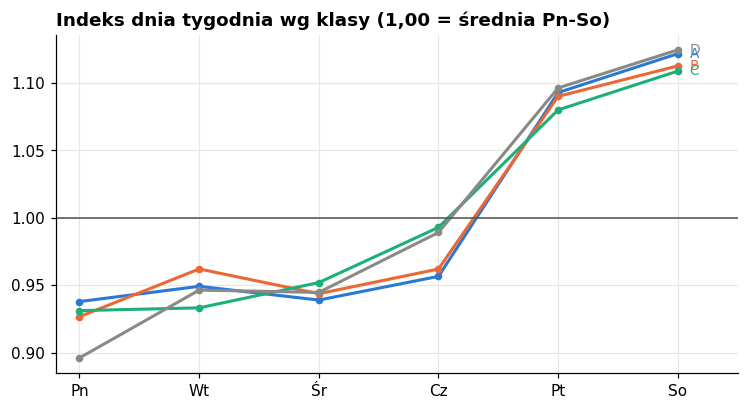

In [26]:
# Indeks dnia tygodnia dla każdej klasy
hd = W[W["Handlowy"] & (W["DzienTyg"] < 6)]
idx_dt = pd.DataFrame({k: hd.groupby("DzienTyg")[k].mean() / hd[k].mean() for k in KLASY + ["Razem"]})
idx_dt.index = DNI[:6]
print(idx_dt.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for k in KLASY:
    ax.plot(idx_dt.index, idx_dt[k], marker="o", ms=4, lw=2, color=KOL[k])
    ax.text(5.1, idx_dt[k].iloc[-1], k, color=KOL[k], va="center", fontsize=9)
ax.axhline(1, color="#52514e", lw=1)
ax.set_xlim(-0.2, 5.5)
ax.set_title("Indeks dnia tygodnia wg klasy (1,00 = średnia Pn-So)")
plt.show()

## 11. Miesiąc wg klasy
Indeks miesiąca: średnia dzienna sprzedaż w miesiącu (dni handlowe Pn-So) podzielona przez średnią tego roku, uśredniona po pełnych latach 2023–2025.

        A     B     C     D  Razem
sty  0.98  0.89  0.71  1.69   0.97
lut  1.01  0.95  0.72  1.89   1.01
mar  1.04  1.01  0.80  2.07   1.05
kwi  1.04  1.04  0.88  1.49   1.05
maj  1.00  1.00  0.85  1.26   1.00
cze  0.96  0.93  0.86  0.99   0.96
lip  0.90  0.88  0.85  0.70   0.90
sie  0.95  0.95  1.01  0.46   0.95
wrz  0.98  0.98  1.10  0.40   0.97
paź  1.01  1.03  1.29  0.37   1.01
lis  1.04  1.08  1.28  0.32   1.03
gru  1.10  1.26  1.66  0.35   1.11


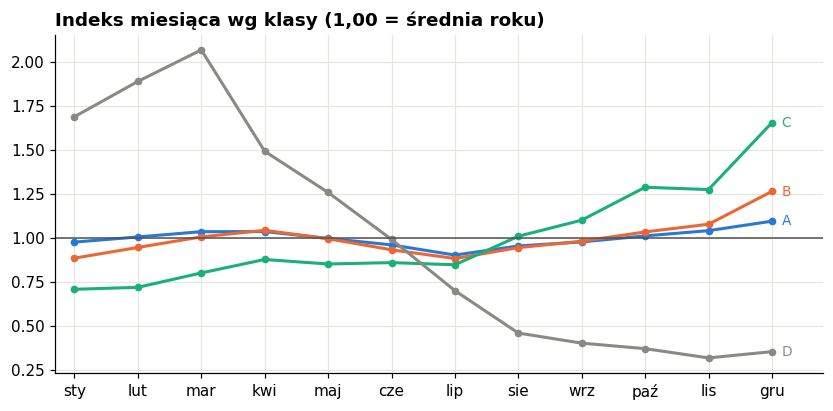

In [27]:
# Indeks miesiąca dla każdej klasy
pe = W[W["Handlowy"] & (W["DzienTyg"] < 6) & W["Rok"].isin([2023, 2024, 2025])]
def indeks_mies(kol_):
    po_roku = pe.groupby(["Rok", "Miesiac"])[kol_].mean().unstack(0)
    return (po_roku / po_roku.mean()).mean(axis=1)
idx_m = pd.DataFrame({k: indeks_mies(k) for k in KLASY + ["Razem"]})
idx_m.index = MIES
print(idx_m.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for k in KLASY:
    ax.plot(MIES, idx_m[k], marker="o", ms=4, lw=2, color=KOL[k])
    ax.text(11.15, idx_m[k].iloc[-1], k, color=KOL[k], va="center", fontsize=9)
ax.axhline(1, color="#52514e", lw=1); ax.set_xlim(-0.3, 11.8)
ax.set_title("Indeks miesiąca wg klasy (1,00 = średnia roku)")
plt.show()

**Jak czytać ten wykres.** Dla A i B indeks to rzeczywista sezonowość (łagodna: grudzień około 1,10 dla A i 1,26 dla B, lipiec około 0,90). Dla C i D to głównie **trend**, a nie sezon: D wygasa (sprzedaż spada do zera w 2025), więc jego indeks maleje przez cały rok, a C rośnie (jego udział w sprzedaży wzrósł z 1 % do 5 %), więc indeks rośnie ku grudniowi. Nie interpretujemy tych dwóch linii jako sezonowości.

## 12. Święta wg klasy
Wskaźnik jak w notebooku o sprzedaży w czasie: dzień / mediana tego samego dnia tygodnia w oknie ±42 dni (bez dni w okolicach świąt), osobno dla każdej klasy.

Boże Narodzenie (25.12)
     -7    -6    -5    -4    -3    -2    -1   0   1     2     3
A  1.16  1.15  1.11  1.17  1.58  1.59  0.88 NaN NaN  0.74  0.88
B  1.41  1.31  1.35  1.47  1.77  2.06  0.99 NaN NaN  0.69  0.82
C  1.39  1.57  1.30  2.00  2.25  2.45  1.27 NaN NaN  0.66  0.85
D  1.34  1.07  1.34  1.89  1.99  2.06   NaN NaN NaN  0.76  0.93

Wielkanoc (niedziela)
   -7    -6    -5    -4    -3    -2    -1   0   1     2     3
A NaN  1.09  1.20  1.27  1.44  1.51  0.85 NaN NaN  0.82  0.95
B NaN  1.18  1.38  1.40  1.67  1.91  1.04 NaN NaN  0.77  0.87
C NaN  1.21  1.57  1.64  2.01  2.75  1.14 NaN NaN  0.75  0.94
D NaN  1.11  1.68  1.71  1.92  3.06  2.12 NaN NaN  0.93  1.06

Wszystkich Świętych (1.11)
     -7    -6    -5    -4    -3    -2    -1   0     1     2     3
A  1.03  0.98  1.08  1.04  1.06  1.13  1.39 NaN  0.96  1.06  1.07
B  1.02  0.95  0.95  1.08  1.05  1.11  1.32 NaN  0.90  0.97  1.11
C  1.08  0.98  0.96  1.29  0.97  1.25  1.91 NaN  0.93  0.87  0.97
D  0.88  1.07  1.18  0.99   NaN

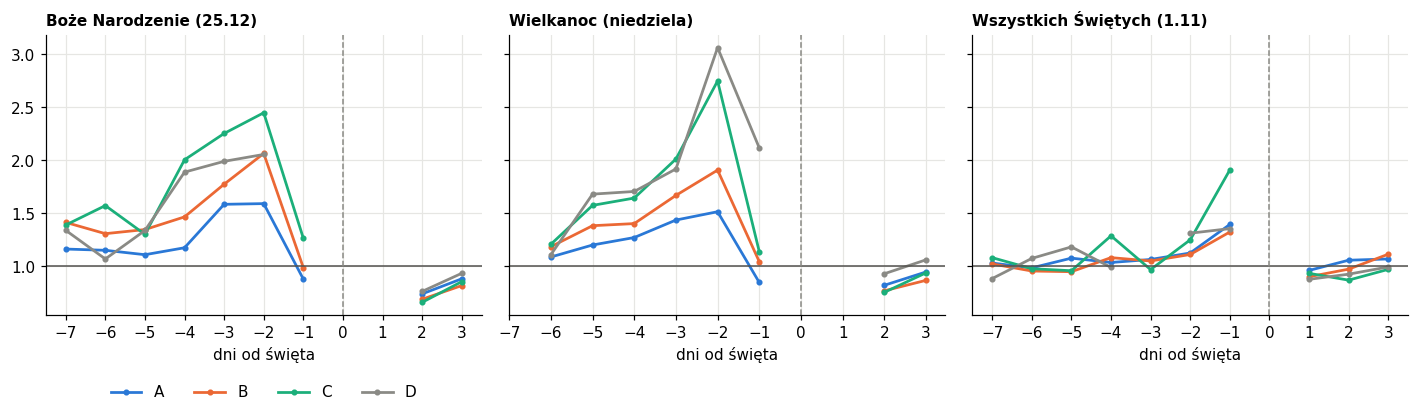

In [28]:
# Wskaźnik względem normy, osobno dla klas
lata = range(W.index.year.min(), W.index.year.max() + 1)
sw = swieta_polska(lata)
dni_sw = pd.DatetimeIndex(sorted(pd.Timestamp(d) for d in sw.keys()))
bl = np.zeros(len(W), dtype=bool)
for d in dni_sw:
    bl |= (np.abs((W.index - d).days) <= 4)
W["BliskoSwieta"] = bl
ok = W["Handlowy"] & (W["DzienTyg"] < 6)
zw = W[ok & ~W["BliskoSwieta"]]

def wskaznik(kol_):
    wyn = pd.Series(np.nan, index=W.index)
    for d in W.index[ok]:
        okno = zw[(zw["DzienTyg"] == d.dayofweek) & (np.abs((zw.index - d).days) <= 42)][kol_]
        if len(okno) >= 3 and okno.median() > 0:
            wyn[d] = W.at[d, kol_] / okno.median()
    return wyn
WS = pd.DataFrame({k: wskaznik(k) for k in KLASY + ["Razem"]})

WYBRANE = {
    "Boże Narodzenie (25.12)": [pd.Timestamp(y, 12, 25) for y in lata],
    "Wielkanoc (niedziela)": [pd.Timestamp(easter(y)) for y in lata],
    "Wszystkich Świętych (1.11)": [pd.Timestamp(y, 11, 1) for y in lata],
}
OFFS = list(range(-7, 4))
prof = {}
for nazwa, daty in WYBRANE.items():
    prof[nazwa] = pd.DataFrame({k: [np.nanmean([WS[k].get(d + pd.Timedelta(days=o), np.nan) for d in daty]) if any(not np.isnan(WS[k].get(d + pd.Timedelta(days=o), np.nan)) for d in daty) else np.nan for o in OFFS] for k in KLASY}, index=OFFS)
for n, t in prof.items():
    print(n); print(t.round(2).T.to_string()); print()

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (n, t) in zip(axs, prof.items()):
    for k in KLASY:
        ax.plot(t.index, t[k], marker="o", ms=3, lw=1.8, color=KOL[k], label=k)
    ax.axhline(1, color="#52514e", lw=1); ax.axvline(0, color=SZARY, lw=1, ls="--")
    ax.set_title(n, fontsize=10); ax.set_xticks(OFFS); ax.set_xlabel("dni od święta")
axs[0].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

## 13. Towary sezonowe w klasach A, B, C
Dla każdego towaru sprawdzamy, czy sprzedaż skupia się w trzech kolejnych miesiącach roku. Towar uznajemy za sezonowy, gdy **w obu latach 2024 i 2025** co najmniej 55 % rocznej wartości przypada na trzy kolejne miesiące (losowy towar miałby około 25 %), a okna szczytu w obu latach różnią się najwyżej o jeden miesiąc. Towary z roczną sprzedażą poniżej 500 zł w którymś z lat pomijamy, bo wynik byłby przypadkowy.

In [29]:
# Koncentracja sprzedaży w 3 kolejnych miesiącach (okno kołowe: lis-sty-lut też się liczy)
s["Rok"] = s["Data"].dt.year
s["Mies"] = s["Data"].dt.month
M = {}
for r in (2024, 2025):
    t = s[s["Rok"] == r].groupby(["SKU", "Mies"])["Wartosc"].sum().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0)
    M[r] = t
wspolne = M[2024].index.intersection(M[2025].index)
wyniki = pd.DataFrame(index=wspolne)
for r in (2024, 2025):
    a = M[r].loc[wspolne].to_numpy()
    suma = a.sum(axis=1)
    okna = a + np.roll(a, -1, axis=1) + np.roll(a, -2, axis=1)
    wyniki[f"Suma_{r}"] = suma
    wyniki[f"Udzial3M_{r}"] = np.where(suma > 0, okna.max(axis=1) / np.where(suma > 0, suma, 1), np.nan)
    wyniki[f"StartSzczytu_{r}"] = okna.argmax(axis=1) + 1
rozn = (wyniki["StartSzczytu_2024"] - wyniki["StartSzczytu_2025"]).abs()
wyniki["RoznicaOkien"] = np.minimum(rozn, 12 - rozn)
wyniki["MaDane"] = (wyniki["Suma_2024"] >= 500) & (wyniki["Suma_2025"] >= 500)
wyniki["CzySezonowyDane"] = (wyniki["MaDane"] & (wyniki["Udzial3M_2024"] >= 0.55) & (wyniki["Udzial3M_2025"] >= 0.55) & (wyniki["RoznicaOkien"] <= 1)).astype("int8")
wyniki["Klasa"] = klasa_tow.reindex(wyniki.index).values
tab_sez = wyniki[wyniki["MaDane"]].groupby("Klasa", observed=False).agg(
    TowaryZDanymi=("CzySezonowyDane", "size"), Sezonowe=("CzySezonowyDane", "sum"))
tab_sez["Sezonowe_%"] = tab_sez["Sezonowe"] / tab_sez["TowaryZDanymi"] * 100
print(tab_sez.reindex(KLASY).fillna(0).round(1).to_string())

       TowaryZDanymi  Sezonowe  Sezonowe_%
Klasa                                     
A             2289.0      19.0         0.8
B               72.0       3.0         4.2
C                0.0       0.0         0.0
D                0.0       0.0         0.0


                                        Nazwa Klasa  Wartosc_24_25  Udzial3M_2024  Udzial3M_2025   Szczyt
SKU                                                                                                      
51629                       ARBUZ CZERWONY KG     A       12725.49           0.55           0.80  cze–sie
51899                 NEKTARYNKA KG HISZPANIA     A        7383.03           0.75           0.95  lip–wrz
66058   LODY TIRAMISU SOS CZEKOLADA 0,9L SPAR     A        6515.00           0.58           0.60  maj–lip
51764               BRZOSKWINIA 1KG HISZPANIA     A        5133.09           0.75           0.89  lip–wrz
17619  SZYSZKA FIGARO Z LIKIEREM ADVOCAT/CZEK     A        4761.35           0.82           0.97  gru–lut
18573          NAPÓJ ENER RED BULL 2PAK 500ML     A        3419.93           0.57           0.99  mar–maj
65702       LODY BURZA CHMURKA MIX 90ML KORAL     A        3086.37           0.60           0.66  kwi–cze
14329    MASŁO EXTRA KOST WARMIA 200G POLMLEK 

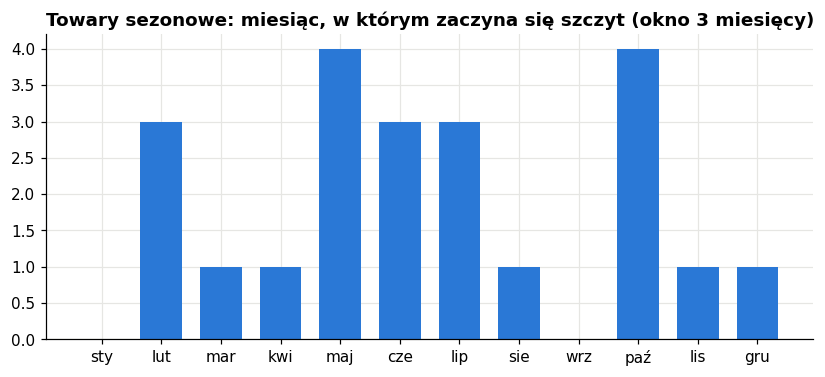

In [30]:
# Najważniejsze towary sezonowe wg wartości w 2024-2025, z oknem szczytu
nazwy = pd.read_parquet(PLIK, columns=["SKU", "NazwaTow"]).drop_duplicates("SKU").set_index("SKU")["NazwaTow"]
sez = wyniki[wyniki["CzySezonowyDane"] == 1].copy()
sez["Wartosc_24_25"] = sez["Suma_2024"] + sez["Suma_2025"]
sez["Szczyt"] = [f"{MIES[(int(a)-1)]}–{MIES[(int(a)+1) % 12]}" for a in sez["StartSzczytu_2025"]]
sez["Nazwa"] = nazwy.reindex(sez.index).astype(str).str.slice(0, 38)
print(sez.sort_values("Wartosc_24_25", ascending=False).head(15)[["Nazwa", "Klasa", "Wartosc_24_25", "Udzial3M_2024", "Udzial3M_2025", "Szczyt"]].round(2).to_string())

# Które miesiące są szczytem dla towarów sezonowych
fig, ax = plt.subplots(figsize=(9, 3.6))
sr = sez["StartSzczytu_2025"].value_counts().reindex(range(1, 13), fill_value=0)
ax.bar(MIES, sr.values, color=NIEB, width=0.7)
ax.set_title("Towary sezonowe: miesiąc, w którym zaczyna się szczyt (okno 3 miesięcy)")
plt.show()

## 14. Wnioski (część II)
- **A to prawie cały sklep:** 22 % towarów daje 79 % wartości. Udział A jest stabilny (77–81 %), więc ogólny wzór tygodnia i roku to w praktyce wzór klasy A.
- **Dzień tygodnia jest wspólny dla wszystkich klas** (piątek i sobota około 1,1, poniedziałek–środa około 0,93). Osobnych indeksów tygodnia dla klas nie trzeba.
- **Sezon roczny jest słaby w A (grudzień 1,10) i mocniejszy w B (1,26).** C i D nie nadają się do oceny sezonu na tych danych (trend zasłania sezon).
- **Święta różnicują klasy:** przed Bożym Narodzeniem i Wielkanocą sprzedaż rośnie we wszystkich klasach, ale im niższa klasa, tym silniej (dwa dni przed Wielkanocą: A około 1,5, B 1,9, C 2,7). Wnioski dla C i D opierają się na małych kwotach, więc są niepewne.
- **Towary sezonowe to głównie A** (owoce, lody, szyszki-likier, energetyki). W klasach C i D nie ma towarów z wystarczającą sprzedażą w 2024–2025 do oceny sezonowości.
- **Klasa D to historia:** jej udział spada z 10 % w 2023 do zera w 2025. W prognozie przyszłości D nie ma znaczenia, ale w danych treningowych wprowadza szum.

## 15. Zapis: jeden plik z cechami dla modelu
Wszystko trafia do **jednego pliku** `dane/interim/cechy_model.parquet`, jeden wiersz na dzień (od 2023-01-01 do 2026-12-31):
- **cechy kalendarzowe i świąteczne** z sekcji 7 (znane z góry, także dla dni po końcu danych),
- **sprzedaż dzienna sklepu** (`Wartosc`, `Sztuki`, `Paragony`, ...) i jej opóźnienia (`Wartosc_lag7` ... `Wartosc_sr4tyg`),
- **sprzedaż dzienna wg klasy** (`Wartosc_A` ... `Wartosc_D`) i jej opóźnienia 7 i 14 dni (`Wartosc_A_lag7` ...).

**Co jest cechą, a co celem.** Kolumny z sprzedażą z tego samego dnia (`Wartosc`, `Sztuki`, `Paragony`, `Pozycje`, `SredniParagon`, `Handlowy`, `Wartosc_A` ... `Wartosc_D`) to **cele lub dane do kontroli**: w chwili prognozy ich nie znamy, więc nie wolno ich podawać modelowi jako cech. Cechami są kolumny kalendarzowe i wszystkie z `_lag` oraz `_sr4tyg` w nazwie. Dni po końcu danych mają puste kolumny sprzedaży.

Nie zapisujemy: indeksów sezonowości klas ani flagi `CzySezonowyDane` (liczone na całych danych, więc dałyby wyciek przyszłości) oraz cech na poziomie towaru (inna ziarnistość: jeden wiersz na towar i dzień to już `fact_inka_final.parquet`).

In [31]:
# Jeden plik: kalendarz + sprzedaż dzienna + sprzedaż wg klas (wszystko po indeksie Data)
cechy = kal.join(dz_model, how="left")

# Opóźnienia liczymy na pełnym kalendarzu (do końca 2026), żeby dni tuż po końcu danych miały je z przeszłości
pelny = dz["Wartosc"].where(dz["Handlowy"]).reindex(cechy.index)       # dni zamknięte = brak, nie zero
for k in (1, 2, 3, 4):
    cechy[f"Wartosc_lag{7 * k}"] = pelny.shift(7 * k)
cechy["Wartosc_sr4tyg"] = cechy[[f"Wartosc_lag{7 * k}" for k in (1, 2, 3, 4)]].mean(axis=1)

wk = W[KLASY].reindex(cechy.index)                        # puste dla dni po końcu danych
for k in KLASY:
    cechy[f"Wartosc_{k}"] = wk[k]
sk = W[KLASY].where(W["Handlowy"], np.nan).reindex(cechy.index)
for k in KLASY:
    for lag in (7, 14):
        cechy[f"Wartosc_{k}_lag{lag}"] = sk[k].shift(lag)

assert cechy.index.is_unique and cechy.index.is_monotonic_increasing
cechy.reset_index().to_parquet("dane/interim/cechy_model.parquet", compression="zstd", index=False)

print("Zapisano: cechy_model.parquet", cechy.shape, "|", cechy.index.min().date(), "…", cechy.index.max().date())
print("Kolumny:", list(cechy.columns))
print("Braki w kolumnach lag (początek danych i dni zamknięte są puste):")
print(cechy.filter(like="lag").isna().sum().to_string())

Zapisano: cechy_model.parquet (1461, 42) | 2023-01-01 … 2026-12-31
Kolumny: ['Rok', 'Miesiac', 'DzienMiesiaca', 'DzienTyg', 'TydzienRoku', 'DzienRoku', 'CzySwieto', 'NazwaSwieta', 'DniDoSwieta', 'DniOdSwieta', 'DzienPrzedSwietem', 'DzienPoSwiecie', 'BliskoSwieta', 'DniDoWielkanocy', 'DniDoBozegoNarodzenia', 'CzyOtwarty', 'CzyNiedzielaHandlowa', 'CzyDlugiWeekend', 'CzyOtwartyRegula', 'Wartosc', 'Sztuki', 'Paragony', 'Pozycje', 'SredniParagon', 'Handlowy', 'Wartosc_lag7', 'Wartosc_lag14', 'Wartosc_lag21', 'Wartosc_lag28', 'Wartosc_sr4tyg', 'Wartosc_A', 'Wartosc_B', 'Wartosc_C', 'Wartosc_D', 'Wartosc_A_lag7', 'Wartosc_A_lag14', 'Wartosc_B_lag7', 'Wartosc_B_lag14', 'Wartosc_C_lag7', 'Wartosc_C_lag14', 'Wartosc_D_lag7', 'Wartosc_D_lag14']
Braki w kolumnach lag (początek danych i dni zamknięte są puste):
Wartosc_lag7       509
Wartosc_lag14      509
Wartosc_lag21      509
Wartosc_lag28      509
Wartosc_A_lag7     509
Wartosc_A_lag14    509
Wartosc_B_lag7     509
Wartosc_B_lag14    509
Wartos